# What is Standardization?

**Standardization** converts the data into a certain range(Generally betweeen -1 to 1) using formula of **Z-score**.
* **Z-score** = (x-mean) / std_deviation

* `For eg`: If there're two columns namely IQ and Salary ranging between 1-10 and 20,000-50,000 respectively, the machine learning algorithm will give more importance to salary.

* After standardizing any column, its `mean` becomes 0 and `std_deviation` becomes 0. It means the data points will come across 0 if we plot them.

Now let's get the answers of the below question with the help of an example.
1) What happens to the outliers after standardization.
2) When to use standardization.

**Note**: `Standardization` and `Normalization` are both two different concepts. We'll study about `Normalization` in our later sessions  

In [13]:
import numpy as np    # Linear algebra
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("24 Social_Network_Ads.csv")

df.sample(5)

# We want only three columns for better understanding that is 'Age'  'Salary' and 'Purchased'

,User ID,Gender,Age,EstimatedSalary,Purchased
296,15673539,Male,42,73000,1
341,15776844,Male,35,75000,0
277,15764604,Male,49,88000,1
348,15579212,Male,39,77000,0
383,15707634,Male,49,28000,1


In [15]:
df = df.iloc[:,2:5]
df.head(3)

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0


In [16]:
x = df[['Age', 'EstimatedSalary']]   # We don't require user_id
y = df.Purchased

print(x)
print(y)



     Age  EstimatedSalary
0     19            19000
1     35            20000
2     26            43000
3     27            57000
4     19            76000
..   ...              ...
395   46            41000
396   51            23000
397   50            20000
398   36            33000
399   49            36000

[400 rows x 2 columns]
0      0
1      0
2      0
3      0
4      0
      ..
395    1
396    1
397    1
398    0
399    1
Name: Purchased, Length: 400, dtype: int64


# Train - Test split

In [17]:
from sklearn.model_selection import train_test_split

In [18]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.3)

print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(280, 2)
(280,)
(120, 2)
(120,)


# Standardizing using **StandardScaler**

`StandardScaler` uses z-score to convert the values.

In [19]:
from sklearn.preprocessing import StandardScaler

# We always fit on train data and transform train and test data both

In [20]:
ss = StandardScaler()

ss.fit(x_train)
# fit means it calculates the mean and std_deviation of 'Age' and 'Salary' in the dataset. 
# Here the columns are 'Age' and 'Salary'.


,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [21]:
# Let's see what mean and std_dev it has calculated?

ss.mean_    # Shows mean of 'Age' and "Salary"
ss.var_

array([1.10029541e+02, 1.17450408e+09])

In [22]:
# In fit, it stores and learn everything i.e mean and std_deviation.
# Then it uses this info to convert when we use 'transform' attribute.

# This takes a dataframe but returns an numpy array

x_train_scaled = ss.transform(x_train)
x_test_scaled = ss.transform(x_test)

print(type(x_train_scaled))
print()
print()
print(x_train_scaled)


# We can use both attributes combined as well
# ss.fit_transforn(x_train)

<class 'numpy.ndarray'>


[[ 0.5508912  -0.95665949]
 [ 0.93222504  0.5314775 ]
 [-0.5931103   1.40685219]
 [-0.02110955 -0.37307636]
 [-0.11644301 -0.43143467]
 [ 1.02755849 -0.95665949]
 [-1.0697776  -0.40225552]
 [ 0.74155812 -0.89830118]
 [-0.68844376  0.06461099]
 [-0.97444414  0.38558171]
 [ 0.83689158 -1.2192719 ]
 [-0.30710993 -0.72322624]
 [ 1.50422579 -0.05210564]
 [-1.83244527 -0.05210564]
 [-1.83244527  0.1229693 ]
 [ 1.88555962 -0.72322624]
 [ 0.83689158 -0.60650961]
 [ 0.83689158 -0.66486793]
 [ 1.59955925  1.55274798]
 [ 1.40889233  2.0779728 ]
 [-1.16511106  0.00625268]
 [-0.30710993 -0.31471805]
 [ 0.26489082 -0.37307636]
 [ 0.26489082 -0.57733046]
 [ 2.07622654 -1.10255527]
 [-0.5931103   0.82326906]
 [-0.40244339  1.17341894]
 [-0.11644301 -0.02292648]
 [ 1.02755849 -1.04419696]
 [-1.26044452  0.44394003]
 [-0.30710993  2.19468942]
 [-0.30710993 -0.40225552]
 [-0.49777685 -0.3438972 ]
 [-1.54644489 -1.56942178]
 [ 1.31355887  1.23177725]
 [-1.16511106 -1.65695925]
 [

In [23]:
# converting numpy array to DataFrame

x_train_scaled_df = pd.DataFrame(x_train_scaled, columns = x_train.columns)
x_test_scaled_df = pd.DataFrame(x_test_scaled, columns = x_test.columns)

In [24]:
x_train_scaled_df

,Age,EstimatedSalary
0,0.550891,-0.956659
1,0.932225,0.531477
2,-0.593110,1.406852
3,-0.021110,-0.373076
4,-0.116443,-0.431435
...,...,...
275,-1.641778,0.006253
276,0.741558,0.064611
277,-1.451111,-0.168822
278,-0.307110,0.006253


In [25]:
# Now let's see what is the mean and std_deviation before and after scaling.

# Before scaling.

print(x_train.describe())

print()
print()
print()

print(x_test.describe())

              Age  EstimatedSalary
count  280.000000       280.000000
mean    38.221429     71785.714286
std     10.508278     34332.401222
min     18.000000     15000.000000
25%     30.000000     47000.000000
50%     37.000000     71000.000000
75%     47.000000     89000.000000
max     60.000000    150000.000000



              Age  EstimatedSalary
count  120.000000       120.000000
mean    36.333333     64975.000000
std     10.346382     33194.224085
min     18.000000     15000.000000
25%     29.000000     35500.000000
50%     36.000000     65000.000000
75%     42.000000     83250.000000
max     60.000000    149000.000000


In [26]:
# After scaling

print(x_train_scaled_df.describe())
print()
print()
print()

print(x_test_scaled_df.describe())

                Age  EstimatedSalary
count  2.800000e+02     2.800000e+02
mean   3.172066e-16    -1.157804e-16
std    1.001791e+00     1.001791e+00
min   -1.927779e+00    -1.656959e+00
25%   -7.837772e-01    -7.232262e-01
50%   -1.164430e-01    -2.292648e-02
75%    8.368916e-01     5.022983e-01
max    2.076227e+00     2.282227e+00



              Age  EstimatedSalary
count  120.000000       120.000000
mean    -0.179999        -0.198731
std      0.986356         0.968579
min     -1.927779        -1.656959
25%     -0.879111        -1.058787
50%     -0.211776        -0.198001
75%      0.360224         0.334518
max      2.076227         2.253048


In [27]:
# As said earlier, after scaling the mean is very near to 0 and std_deviation is very near to 1 
# moreover, we need to convert the numpy array we got after scaling to dataframe bcz only dataframe has describe() function.

# Let's visualize what happend after scaling. 

In [28]:
fig, (n1, n2) = plt.subplots(ncols = 2, fig_size = (12, 5))

#sns.scatterplot(x = 'Age', y = 'EstimatedSalary', data = df)
#plt.title("Before scaling")

n1.scatter()

AttributeError: Figure.set() got an unexpected keyword argument 'fig_size'

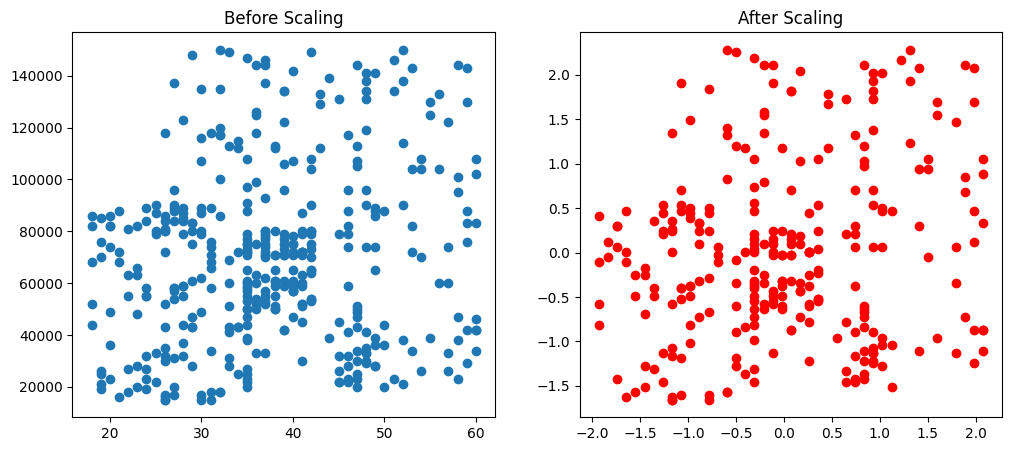

In [29]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

ax1.scatter(x = 'Age', y = 'EstimatedSalary', data = df)
ax1.set_title("Before Scaling")
ax2.scatter(x= 'Age', y = 'EstimatedSalary', data = x_train_scaled_df, color='red')
ax2.set_title("After Scaling")
plt.show()

In [30]:
# We can see thet there is no difference in the distribution which even should not be,as expected, scale is changed.
# We can see on x-axis

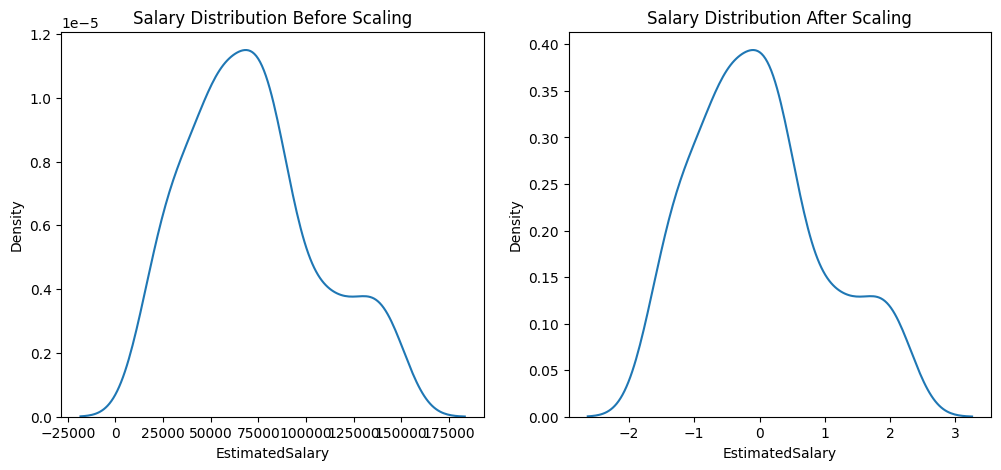

In [31]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before scaling

ax1.set_title('Salary Distribution Before Scaling')
sns.kdeplot(x_train['EstimatedSalary'], ax=ax1)

# after scaling

ax2.set_title('Salary Distribution After Scaling')
sns.kdeplot(x_train_scaled_df['EstimatedSalary'], ax =ax2)
plt.show()

# Why scaling is important??

In [32]:
from sklearn.linear_model import LogisticRegression

In [33]:
lr = LogisticRegression()
lr_scaled = LogisticRegression()

In [34]:
lr.fit(x_train, y_train)    # Training with unscaled dataframe

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [35]:
lr_scaled.fit(x_train_scaled_df, y_train)    # Training with scaled dataframe

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [36]:
y_pred_unscaled = lr.predict(x_test)
y_pred_scaled = lr_scaled.predict(x_test_scaled_df)

In [37]:
# Getting accuracy scored of both, scaled and unscaled.

from sklearn.metrics import accuracy_score

In [38]:
accuracy_unscaled = accuracy_score(y_pred_unscaled, y_test)
accuracy_scaled = accuracy_score(y_pred_scaled, y_test)

print(f"Accuracy on unscaled dataframe = {accuracy_unscaled}.\nAccuracy on scaled dataframe = {accuracy_scaled}.")

Accuracy on unscaled dataframe = 0.825.
Accuracy on scaled dataframe = 0.825.


# We can clearly see the difference in the accuracy we are getting with scaled data and unscaled data.

Note: There's no effect of scaling on **Decision tree**. Let's try with **Decision tree** model.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

In [ ]:
dt = DecisionTreeClassifier()
dt_scaled = DecisionTreeClassifier()

In [ ]:
dt.fit(x_train, y_train)              # Unscaled
dt_scaled.fit(x_train_scaled_df, y_train)    # Scaled

DecisionTreeClassifier()

In [ ]:
y_pred_unscaled = dt.predict(x_test)
y_pred_scaled = dt_scaled.predict(x_test_scaled_df)

In [ ]:
accuracy_unscaled = accuracy_score(y_pred_unscaled, y_test)
accuracy_scaled = accuracy_score(y_pred_scaled, y_test)

print(f"Accuracy unscaled = {accuracy_unscaled}\nAccuracy Scaled = {accuracy_scaled}")

Accuracy unscaled = 0.7916666666666666
Accuracy Scaled = 0.8


# We can see, there's no difference in accuracy when we train decision tree model on scaled and unscaled data.

# What happens to outliers?
Outliers remains as it is. There'll be no effect to outliers after scaling, so we always need to deal with it seperately,

# Which algorithm requires `scaling`?
1) K- Means
2) KNearestNeighbors
3) Principal Components Analysis
4) Artificial Neural Network
5) Gradient Descent

# Which algorithm doesn't requires `scaling`?(Scaling doesn't make any difference whether we perform it or not.)
1) Decision Tree
2) Random Forest
3) Gradiend Boost
4) XG Boost


# Day 25: Feature scaling(Normalization).(Not getting clear in CampusX's video)
# Day 26: Encoding categorical data